# Entrega 3 — Rendimientos, volatilidad y simulación de precios

**Activo:** Grupo México, serie B (GMEXICOB.MX) · **Materia:** Análisis del Riesgo · ITESO

In [1]:
# Librerías, rutas y datos
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

ruta_src = os.path.abspath(os.path.join("..", "src"))
if ruta_src not in sys.path:
    sys.path.append(ruta_src)

from calculo_rendimientos import calculate_returns
from estadistica import (resumen_anual, parametros_historicos, prueba_normalidad,
                         prueba_media_cero, dias_extremos, DIAS_HABILES)
from modelos_precio import modelo_diario, modelo_lognormal

GMEXICO_PATH = os.path.join("..", "datos_historicos", "gmexico_prices.csv")
GRAFICAS = os.path.join("..", "graficas")

df = calculate_returns(GMEXICO_PATH)
r = df["log_return"]
par = parametros_historicos(r)
S0 = df["adj_close"].iloc[-1]
fecha_S0 = df.index[-1]

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, ROJO, VERDE, GRIS = "#1f77b4", "#c0392b", "#2e8b57", "#7f8c8d"

def pct(x, d=2):
    return f"{x * 100:.{d}f}%"

def guardar(fig, nombre):
    fig.savefig(os.path.join(GRAFICAS, f"{nombre}.png"), dpi=300, bbox_inches="tight")

display(Markdown(
    f"Datos: precio ajustado diario de **{df.index[0]:%d-%m-%Y}** a **{fecha_S0:%d-%m-%Y}** "
    f"({len(r):,} rendimientos diarios). Último precio observado: **S₀ = {S0:,.2f} MXN**."
))

Datos: precio ajustado diario de **04-01-2000** a **14-09-2026** (6,773 rendimientos diarios). Último precio observado: **S₀ = 213.91 MXN**.

## Parte 1 — Rendimientos y volatilidad

In [2]:
anual = resumen_anual(df)
anual_completos = anual[anual["dias"] >= 240]   # excluye el año en curso si está incompleto
anio_actual = anual.index[-1]

mejor = anual_completos["mu_anual"].idxmax()
peor = anual_completos["mu_anual"].idxmin()
mas_vol = anual_completos["sigma_anual"].idxmax()
menos_vol = anual_completos["sigma_anual"].idxmin()

def resumen(a):
    f = anual.loc[a]
    return f"**{a}** (μ = {pct(f.mu_anual, 1)}, equivalente a {pct(f.rend_simple_equiv, 1)} simple)"

display(Markdown(f'''
**¿Qué se hizo?** Se midió el rendimiento medio y la volatilidad de GMEXICOB para cada año, de
{anual.index[0]} a {anio_actual}, en escala diaria y anualizada.

**¿Cómo se hizo?** Con el precio ajustado diario se calcularon rendimientos logarítmicos. Para cada año
se obtuvo su media y su desviación estándar diaria, y se anualizaron con 252 días hábiles.

**¿Qué resultados se obtuvieron?** El mejor año fue {resumen(mejor)} y el peor {resumen(peor)}.
El año más volátil fue **{mas_vol}** (σ anual = {pct(anual.loc[mas_vol, "sigma_anual"], 1)}) y el más
tranquilo **{menos_vol}** ({pct(anual.loc[menos_vol, "sigma_anual"], 1)}). En todo el historial, el
rendimiento medio anualizado es {pct(par["mu_anual"], 1)} con una volatilidad de {pct(par["sigma_anual"], 1)}.
'''))


**¿Qué se hizo?** Se midió el rendimiento medio y la volatilidad de GMEXICOB para cada año, de
2000 a 2026, en escala diaria y anualizada.

**¿Cómo se hizo?** Con el precio ajustado diario se calcularon rendimientos logarítmicos. Para cada año
se obtuvo su media y su desviación estándar diaria, y se anualizaron con 252 días hábiles.

**¿Qué resultados se obtuvieron?** El mejor año fue **2009** (μ = 126.8%, equivalente a 255.2% simple) y el peor **2001** (μ = -116.2%, equivalente a -68.7% simple).
El año más volátil fue **2008** (σ anual = 70.2%) y el más
tranquilo **2012** (22.3%). En todo el historial, el
rendimiento medio anualizado es 17.4% con una volatilidad de 38.4%.


### Marco teórico

El rendimiento logarítmico diario mide el cambio porcentual continuo del precio entre dos días:

$$r_t = \ln\left(\frac{S_t}{S_{t-1}}\right)$$

Para cada año con $n$ días hábiles, el rendimiento medio y la volatilidad diarios son:

$$\bar r_d = \frac{1}{n}\sum_{t=1}^{n} r_t \qquad\qquad \sigma_d = \sqrt{\frac{1}{n-1}\sum_{t=1}^{n}\left(r_t-\bar r_d\right)^2}$$

Se anualizan con 252 días hábiles. La media escala con el tiempo y la volatilidad con su raíz cuadrada,
porque si los rendimientos diarios son independientes sus varianzas se suman:

$$\mu_{anual} = 252\,\bar r_d \qquad\qquad \sigma_{anual} = \sqrt{252}\,\sigma_d$$

Como $\mu_{anual}$ es un rendimiento logarítmico, su equivalente en rendimiento simple es $e^{\mu_{anual}}-1$.

### Tabla por año

In [3]:
tabla1 = anual.rename(columns={
    "dias": "Días", "mu_diario": "μ diario", "sigma_diaria": "σ diaria",
    "mu_anual": "μ anual", "sigma_anual": "σ anual", "rend_simple_equiv": "Rend. simple equiv.",
})
tabla1.index.name = "Año"

def resaltar(fila):
    color = {mejor: "#d5f5e3", peor: "#fadbd8", mas_vol: "#fdebd0"}.get(fila.name, "")
    return [f"background-color: {color}" if color else "" for _ in fila]

display(
    tabla1.style
    .format({"μ diario": "{:.4%}", "σ diaria": "{:.4%}", "μ anual": "{:.2%}",
             "σ anual": "{:.2%}", "Rend. simple equiv.": "{:.2%}"})
    .apply(resaltar, axis=1)
)
nota = f" {anio_actual} tiene {anual.loc[anio_actual, 'dias']} días (año en curso)." if anual.loc[anio_actual, "dias"] < 240 else ""
display(Markdown(f"Verde: mejor año · Rojo: peor año · Naranja: mayor volatilidad.{nota}"))

,Días,μ diario,σ diaria,μ anual,σ anual,Rend. simple equiv.
Año,,,,,,
2000,259,-0.1565%,2.8710%,-39.44%,45.58%,-32.59%
2001,261,-0.4611%,2.6943%,-116.21%,42.77%,-68.72%
2002,261,0.0939%,3.2818%,23.67%,52.10%,26.70%
2003,261,0.3572%,2.2244%,90.02%,35.31%,146.00%
2004,262,0.2549%,1.9585%,64.24%,31.09%,90.10%
2005,260,0.1257%,1.9594%,31.66%,31.11%,37.25%
2006,260,0.2058%,2.3507%,51.86%,37.32%,67.97%
2007,253,0.2422%,2.6774%,61.03%,42.50%,84.11%
2008,253,-0.3509%,4.4227%,-88.43%,70.21%,-58.70%


Verde: mejor año · Rojo: peor año · Naranja: mayor volatilidad. 2026 tiene 176 días (año en curso).

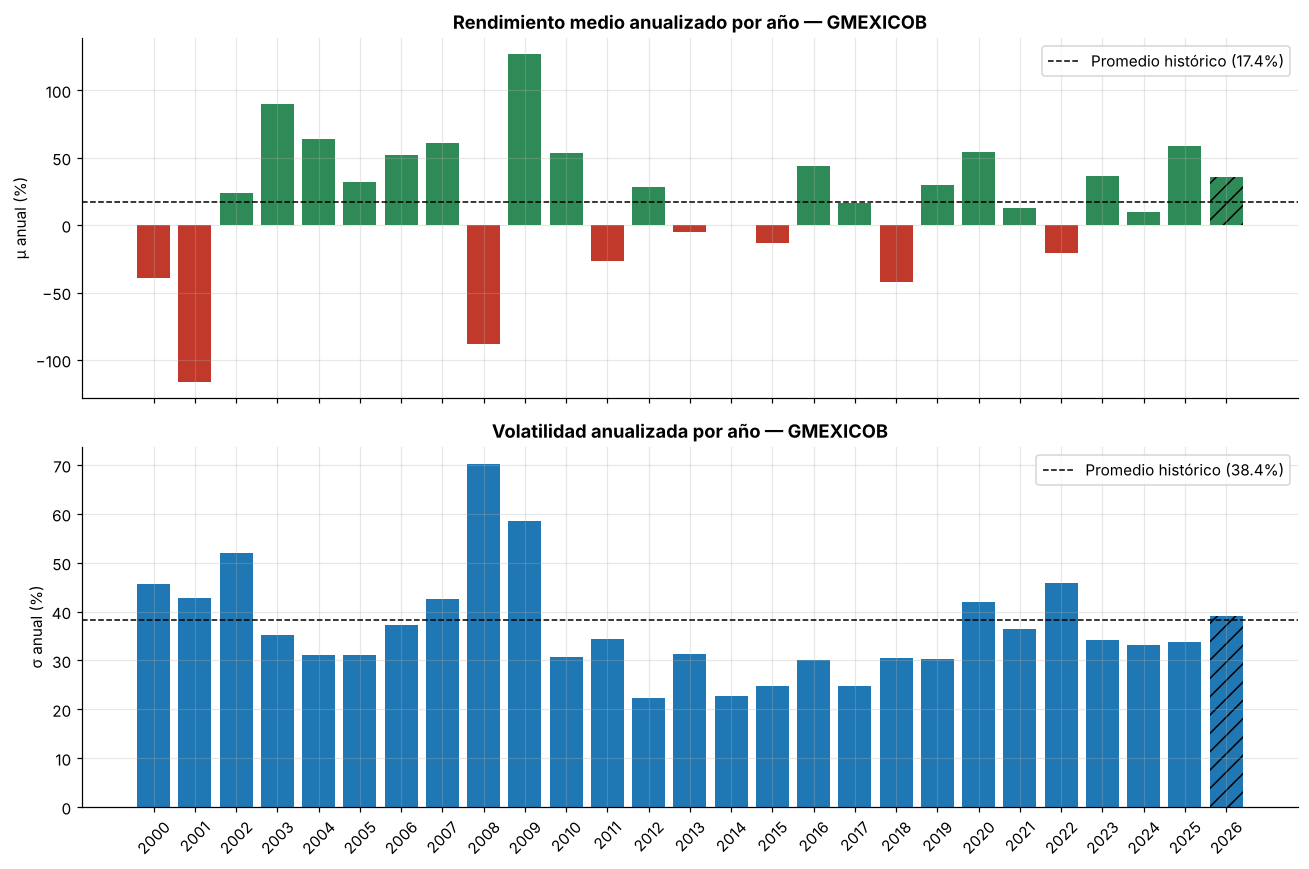

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
anios = anual.index.astype(str)

colores = [VERDE if v >= 0 else ROJO for v in anual["mu_anual"]]
parcial = ["//" if d < 240 else "" for d in anual["dias"]]
barras = ax[0].bar(anios, anual["mu_anual"] * 100, color=colores)
for b, h in zip(barras, parcial):
    b.set_hatch(h)
ax[0].axhline(par["mu_anual"] * 100, color="black", ls="--", lw=1,
              label=f"Promedio histórico ({pct(par['mu_anual'], 1)})")
ax[0].set_ylabel("μ anual (%)")
ax[0].set_title("Rendimiento medio anualizado por año — GMEXICOB", fontweight="bold")
ax[0].legend(loc="upper right")

barras = ax[1].bar(anios, anual["sigma_anual"] * 100, color=AZUL)
for b, h in zip(barras, parcial):
    b.set_hatch(h)
ax[1].axhline(par["sigma_anual"] * 100, color="black", ls="--", lw=1,
              label=f"Promedio histórico ({pct(par['sigma_anual'], 1)})")
ax[1].set_ylabel("σ anual (%)")
ax[1].set_title("Volatilidad anualizada por año — GMEXICOB", fontweight="bold")
ax[1].legend(loc="upper right")
plt.xticks(rotation=45)

plt.tight_layout()
guardar(fig, "e3_rendimiento_volatilidad_anual")
plt.show()

### Relación con eventos reales

- **2009, mejor año.** Rebote después de la crisis financiera. El cobre se recuperó con fuerza por el estímulo
  económico de China y la reactivación global. Coincide con la "recuperación en V" identificada en la Entrega 2.
- **2001, peor año.** Recesión en Estados Unidos tras la burbuja puntocom, precio del cobre en mínimos de varios
  años y alto endeudamiento de Grupo México después de la compra de Asarco en 1999. Coincide con la fase de
  consolidación en mínimos de 2000–2003.
- **2008, mayor volatilidad y segundo peor año.** Crisis financiera global, quiebra de Lehman Brothers (septiembre)
  y desplome del cobre. Tres de los cinco peores días de toda la historia de la acción ocurrieron entre
  septiembre y octubre de 2008.
- **2012 y 2014, menor volatilidad.** Corresponden a la consolidación lateral de 2011–2015, sin grandes choques.
- **2020** vuelve a mostrar volatilidad alta por el COVID-19, pero cierra con rendimiento positivo por el rebote
  de los metales en la segunda mitad del año.

## Parte 2 — Pruebas de normalidad y prueba de hipótesis

In [5]:
variables = {
    "Rendimiento log diario": r,
    "Precio": df["adj_close"],
    "Logaritmo del precio": np.log(df["adj_close"]),
}
normalidad = pd.DataFrame([prueba_normalidad(s, n) for n, s in variables.items()]).set_index("variable")
ext = dias_extremos(r, k=3)
tt = prueba_media_cero(r)

rechazos = (normalidad["valor_p"] < 0.05).sum()
k_r = normalidad.loc["Rendimiento log diario", "curtosis"]

display(Markdown(f'''
**¿Qué se hizo?** Con todo el historial se probó si el rendimiento diario, el precio y el logaritmo del precio
siguen una distribución normal, y si el rendimiento promedio es estadísticamente distinto de cero.

**¿Cómo se hizo?** Se aplicó la prueba de Jarque-Bera con α = 0.05 a cada variable y se comparó su histograma
contra la curva normal teórica. Para la media se usó una prueba t de una muestra.

**¿Qué resultados se obtuvieron?** Se rechaza la normalidad en las {rechazos} variables (valor p ≈ 0).
El rendimiento tiene una curtosis de {k_r:.2f}, contra 3 de una normal: hay colas pesadas. El
{pct(ext["observado"])} de los días tuvo movimientos mayores a 3σ, cuando una normal predice
{pct(ext["esperado"])}, es decir, {ext["veces_mas"]:.1f} veces más días extremos. La prueba t da
t = {tt["t"]:.2f} con valor p = {tt["valor_p"]:.4f}, así que {"se rechaza" if tt["valor_p"] < 0.05 else "no se rechaza"}
que el rendimiento medio sea cero.
'''))


**¿Qué se hizo?** Con todo el historial se probó si el rendimiento diario, el precio y el logaritmo del precio
siguen una distribución normal, y si el rendimiento promedio es estadísticamente distinto de cero.

**¿Cómo se hizo?** Se aplicó la prueba de Jarque-Bera con α = 0.05 a cada variable y se comparó su histograma
contra la curva normal teórica. Para la media se usó una prueba t de una muestra.

**¿Qué resultados se obtuvieron?** Se rechaza la normalidad en las 3 variables (valor p ≈ 0).
El rendimiento tiene una curtosis de 7.79, contra 3 de una normal: hay colas pesadas. El
1.49% de los días tuvo movimientos mayores a 3σ, cuando una normal predice
0.27%, es decir, 5.5 veces más días extremos. La prueba t da
t = 2.36 con valor p = 0.0185, así que se rechaza
que el rendimiento medio sea cero.


### 2.1 Prueba de normalidad: Jarque-Bera

**¿Por qué Jarque-Bera?**

1. Mide directamente el sesgo y la curtosis, que es justo donde los rendimientos financieros suelen alejarse de la
   normal (colas pesadas y asimetría).
2. Su distribución bajo $H_0$ es asintótica, y con casi 6,800 observaciones esa aproximación es muy buena.
   Shapiro-Wilk, en cambio, pierde precisión en su valor p con más de 5,000 datos.

El estadístico compara el sesgo $S$ y la curtosis $K$ de la muestra contra los de una normal ($S=0$, $K=3$):

$$JB = \frac{n}{6}\left(S^2 + \frac{(K-3)^2}{4}\right) \sim \chi^2_{(2)} \quad \text{bajo } H_0$$

$$S = \frac{\frac{1}{n}\sum (x_t-\bar x)^3}{\hat\sigma^3} \qquad\qquad K = \frac{\frac{1}{n}\sum (x_t-\bar x)^4}{\hat\sigma^4}$$

- $H_0$: la variable se distribuye normal.
- $H_1$: la variable no se distribuye normal.
- Se rechaza $H_0$ si el valor p < 0.05 (equivalente a $JB > 5.99$).

**¿Qué dice la teoría?** El modelo de precios supone que el rendimiento logarítmico es normal. Eso implica que
el precio futuro es **lognormal** (no normal), y que su logaritmo sí es normal para un horizonte dado.

In [6]:
tabla2 = normalidad.rename(columns={"n": "n", "sesgo": "Sesgo (S)", "curtosis": "Curtosis (K)",
                                    "JB": "Estadístico JB", "valor_p": "Valor p", "conclusion": "Conclusión"})
tabla2.index.name = "Variable"
display(tabla2.style.format({"Sesgo (S)": "{:.4f}", "Curtosis (K)": "{:.4f}",
                             "Estadístico JB": "{:,.2f}", "Valor p": "{:.2e}"}))

,n,Sesgo (S),Curtosis (K),Estadístico JB,Valor p,Conclusión
Variable,,,,,,
Rendimiento log diario,6773,-0.0965,7.7862,"6,475.12",0.00e+00,Se rechaza H0: no es normal
Precio,6773,2.2008,8.7213,"14,704.92",0.00e+00,Se rechaza H0: no es normal
Logaritmo del precio,6773,-0.6173,2.3326,555.82,2.02e-121,Se rechaza H0: no es normal


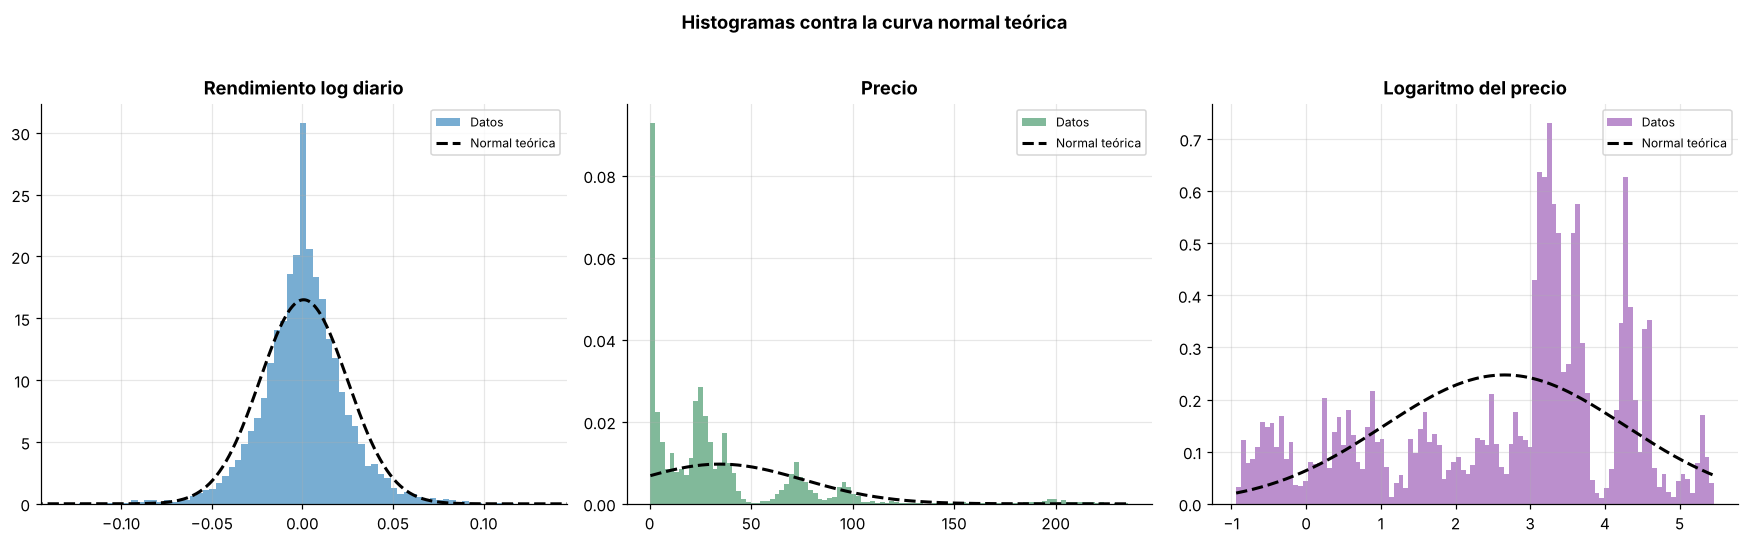

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
colores = [AZUL, VERDE, "#8e44ad"]

for ax, (nombre, serie), color in zip(axes, variables.items(), colores):
    x = serie.dropna()
    ax.hist(x, bins=100, density=True, color=color, alpha=0.6, label="Datos")
    grid = np.linspace(x.min(), x.max(), 400)
    ax.plot(grid, stats.norm.pdf(grid, x.mean(), x.std()), "k--", lw=2, label="Normal teórica")
    ax.set_title(nombre, fontweight="bold")
    ax.legend(fontsize=8)

axes[0].set_xlim(r.mean() - 6 * r.std(), r.mean() + 6 * r.std())
fig.suptitle("Histogramas contra la curva normal teórica", fontweight="bold", y=1.02)
plt.tight_layout()
guardar(fig, "e3_histogramas_normalidad")
plt.show()

**Interpretación.** El rendimiento diario tiene forma de campana, pero más puntiaguda en el centro y con colas
más largas que la normal: hay más días muy tranquilos y más días extremos de lo que el modelo predice. El precio
está sesgado a la derecha porque pasó largos periodos en niveles bajos y subió exponencialmente en los últimos años.
El logaritmo del precio tampoco es normal en el historial porque es una serie con tendencia, no una muestra
independiente; la teoría solo predice normalidad de $\ln S_T$ para un horizonte fijo partiendo de $S_0$.

### 2.2 Prueba de hipótesis: ¿el rendimiento promedio es distinto de cero?

$$H_0:\ \mu = 0 \qquad\qquad H_1:\ \mu \neq 0$$

$$t = \frac{\bar r}{s/\sqrt{n}} \sim t_{(n-1)}$$

Se rechaza $H_0$ si $|t| > t_{0.975,\,n-1} \approx 1.96$ o si el valor p < 0.05. Aunque los rendimientos no son
normales, con $n$ tan grande el Teorema del Límite Central garantiza que $\bar r$ sí es aproximadamente normal,
así que la prueba es válida.

In [8]:
tabla3 = pd.DataFrame({
    "Valor": [f"{tt['n']:,}", f"{tt['media']:.6f}", f"{tt['desv_est']:.6f}", f"{tt['error_est']:.6f}",
              f"{tt['t']:.4f}", f"±{tt['t_critico']:.4f}", f"{tt['valor_p']:.4f}", tt["conclusion"]]
}, index=["n", "Media diaria", "Desviación estándar", "Error estándar", "Estadístico t",
          "t crítico (95%)", "Valor p", "Conclusión"])
display(tabla3)

ic_inf = (tt["media"] - 1.96 * tt["error_est"]) * DIAS_HABILES
ic_sup = (tt["media"] + 1.96 * tt["error_est"]) * DIAS_HABILES
display(Markdown(
    f"**Interpretación.** La media diaria de {pct(tt['media'], 4)} es pequeña, pero con {tt['n']:,} datos "
    f"resulta estadísticamente distinta de cero. Anualizada equivale a {pct(par['mu_anual'], 1)}, con un "
    f"intervalo de confianza del 95% de **[{pct(ic_inf, 1)}, {pct(ic_sup, 1)}]**: el signo positivo es "
    f"confiable, pero la magnitud es muy imprecisa."
))

,Valor
n,"6,773"
Media diaria,0.000692
Desviación estándar,0.024178
Error estándar,0.000294
Estadístico t,2.3563
t crítico (95%),±1.9603
Valor p,0.0185
Conclusión,Se rechaza H0: mu distinto de 0


**Interpretación.** La media diaria de 0.0692% es pequeña, pero con 6,773 datos resulta estadísticamente distinta de cero. Anualizada equivale a 17.4%, con un intervalo de confianza del 95% de **[2.9%, 32.0%]**: el signo positivo es confiable, pero la magnitud es muy imprecisa.

## Parte 3 — Modelo diario del precio

In [9]:
mu_d, sig_d = par["mu_diario"], par["sigma_diaria"]
diario, sims_d = modelo_diario(S0, mu_d, sig_d, horizontes=(10, 20, 40), n_sim=10_000)

def linea(h, t, unidad):
    f = t.loc[h]
    return f"- {h} {unidad}: **{f['E[S_T] teorico']:,.2f} MXN**, IC 95% [{f['IC95 inf']:,.2f}, {f['IC95 sup']:,.2f}]"

display(Markdown(f'''
**¿Qué se hizo?** Se estimó el precio de GMEXICOB a 10, 20 y 40 días hábiles con el modelo diario de cambio
en el precio.

**¿Cómo se hizo?** Con los parámetros diarios de todo el historial (μ = {pct(mu_d, 4)}, σ = {pct(sig_d, 3)})
y el último precio S₀ = {S0:,.2f} MXN ({fecha_S0:%d-%m-%Y}), se generaron 10,000 valores aleatorios ε ~ N(0,1)
para cada horizonte y se calculó el precio con la ecuación del modelo.

**¿Qué resultados se obtuvieron?**

{linea(10, diario, "días")}
{linea(20, diario, "días")}
{linea(40, diario, "días")}

La simulación coincide con la fórmula teórica en todos los horizontes.
'''))


**¿Qué se hizo?** Se estimó el precio de GMEXICOB a 10, 20 y 40 días hábiles con el modelo diario de cambio
en el precio.

**¿Cómo se hizo?** Con los parámetros diarios de todo el historial (μ = 0.0692%, σ = 2.418%)
y el último precio S₀ = 213.91 MXN (14-09-2026), se generaron 10,000 valores aleatorios ε ~ N(0,1)
para cada horizonte y se calculó el precio con la ecuación del modelo.

**¿Qué resultados se obtuvieron?**

- 10 días: **215.39 MXN**, IC 95% [183.34, 247.45]
- 20 días: **216.87 MXN**, IC 95% [171.54, 262.21]
- 40 días: **219.83 MXN**, IC 95% [155.72, 283.94]

La simulación coincide con la fórmula teórica en todos los horizontes.


### Marco teórico

El cambio en el precio en un intervalo $\Delta t$ es la suma de una tendencia y un choque aleatorio:

$$\Delta S = \mu\, S_0\, \Delta t + \sigma\, S_0\, \varepsilon \sqrt{\Delta t}, \qquad \varepsilon \sim N(0,1)$$

Como $\mu$ y $\sigma$ son **diarios**, $\Delta t$ se mide en **días** ($\Delta t = 10, 20, 40$). El precio
estimado es $S_T = S_0 + \Delta S$. Como $\varepsilon$ es normal, $S_T$ también lo es:

$$E[S_T] = S_0\,(1 + \mu\,\Delta t) \qquad\qquad \text{Var}(S_T) = \sigma^2 S_0^2\,\Delta t$$

$$IC_{95\%} = E[S_T] \pm 1.96\,\sigma\,S_0\sqrt{\Delta t}$$

El intervalo es simétrico y su ancho crece con $\sqrt{\Delta t}$: pasar de 10 a 40 días (4 veces más tiempo)
solo duplica la incertidumbre.

In [10]:
COLS = {"E[S_T] teorico": "E[S_T] teórico", "IC95 inf": "IC 95% inf.", "IC95 sup": "IC 95% sup.",
        "E[S_T] simulado": "E[S_T] simulado", "IC95 inf sim": "IC 95% inf. (sim.)",
        "IC95 sup sim": "IC 95% sup. (sim.)", "T (anios)": "T (años)"}
tabla4 = diario.rename(columns=COLS)
tabla4.index.name = "Horizonte (días)"
display(tabla4.style.format("${:,.2f}"))

,E[S_T] teórico,IC 95% inf.,IC 95% sup.,E[S_T] simulado,IC 95% inf. (sim.),IC 95% sup. (sim.)
Horizonte (días),,,,,,
10,$215.39,$183.34,$247.45,$215.22,$183.13,$247.60
20,$216.87,$171.54,$262.21,$217.34,$172.25,$262.85
40,$219.83,$155.72,$283.94,$220.30,$155.91,$285.34


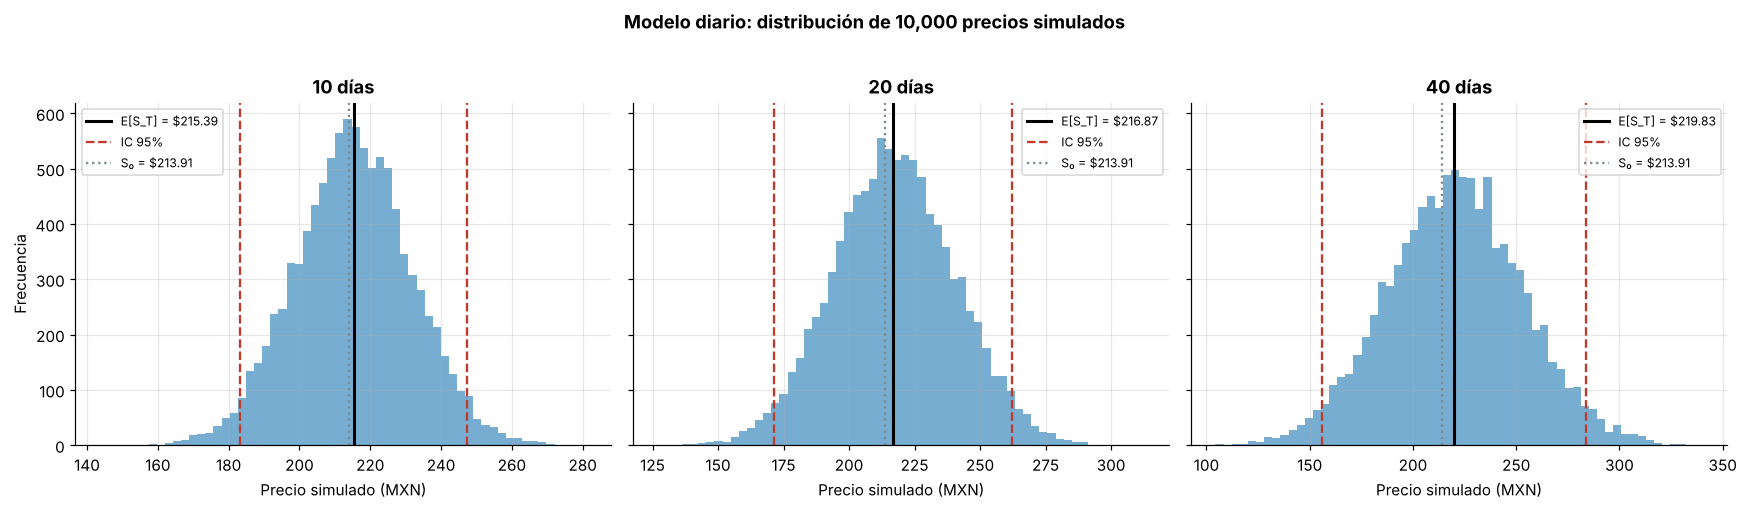

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, h in zip(axes, diario.index):
    f = diario.loc[h]
    ax.hist(sims_d[h], bins=60, color=AZUL, alpha=0.6)
    ax.axvline(f["E[S_T] teorico"], color="black", lw=2, label=f"E[S_T] = ${f['E[S_T] teorico']:,.2f}")
    ax.axvline(f["IC95 inf"], color=ROJO, ls="--", lw=1.5, label="IC 95%")
    ax.axvline(f["IC95 sup"], color=ROJO, ls="--", lw=1.5)
    ax.axvline(S0, color=GRIS, ls=":", lw=1.5, label=f"S₀ = ${S0:,.2f}")
    ax.set_title(f"{h} días", fontweight="bold")
    ax.set_xlabel("Precio simulado (MXN)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Frecuencia")
fig.suptitle("Modelo diario: distribución de 10,000 precios simulados", fontweight="bold", y=1.02)
plt.tight_layout()
guardar(fig, "e3_modelo_diario_histogramas")
plt.show()

## Parte 4 — Modelo lognormal anual

In [12]:
mu_a, sig_a = par["mu_anual"], par["sigma_anual"]
lognormal, sims_a = modelo_lognormal(S0, mu_a, sig_a, meses=(3, 6, 9, 12), n_sim=10_000)

display(Markdown(f'''
**¿Qué se hizo?** Se estimó el precio de GMEXICOB a 3, 6, 9 y 12 meses con el modelo lognormal.

**¿Cómo se hizo?** Con los parámetros anuales de todo el historial (μ = {pct(mu_a, 2)}, σ = {pct(sig_a, 2)}),
S₀ = {S0:,.2f} MXN y T en años (0.25, 0.50, 0.75 y 1), se simularon 10,000 valores de ε ~ N(0,1) por horizonte
en la ecuación del logaritmo del precio.

**¿Qué resultados se obtuvieron?**

{linea(3, lognormal, "meses")}
{linea(6, lognormal, "meses")}
{linea(9, lognormal, "meses")}
{linea(12, lognormal, "meses")}

A diferencia del modelo diario, los intervalos son asimétricos: el precio puede subir más de lo que puede bajar.
'''))


**¿Qué se hizo?** Se estimó el precio de GMEXICOB a 3, 6, 9 y 12 meses con el modelo lognormal.

**¿Cómo se hizo?** Con los parámetros anuales de todo el historial (μ = 17.44%, σ = 38.38%),
S₀ = 213.91 MXN y T en años (0.25, 0.50, 0.75 y 1), se simularon 10,000 valores de ε ~ N(0,1) por horizonte
en la ecuación del logaritmo del precio.

**¿Qué resultados se obtuvieron?**

- 3 meses: **223.45 MXN**, IC 95% [150.60, 319.54]
- 6 meses: **233.41 MXN**, IC 95% [132.16, 382.94]
- 9 meses: **243.81 MXN**, IC 95% [120.26, 442.59]
- 12 meses: **254.68 MXN**, IC 95% [111.51, 502.01]

A diferencia del modelo diario, los intervalos son asimétricos: el precio puede subir más de lo que puede bajar.


### Marco teórico

Si el rendimiento logarítmico es normal, el logaritmo del precio al tiempo $T$ (en **años**) es:

$$\ln S_T = \ln S_0 + \left(\mu - \tfrac{1}{2}\sigma^2\right)T + \sigma\,\varepsilon\sqrt{T}, \qquad \varepsilon \sim N(0,1)$$

Por lo tanto $\ln S_T$ es normal y $S_T$ es **lognormal**. El valor esperado y el intervalo de confianza son:

$$E[S_T] = S_0\, e^{\mu T} \qquad\qquad IC_{95\%} = \exp\left[\ln S_0 + \left(\mu - \tfrac{1}{2}\sigma^2\right)T \pm 1.96\,\sigma\sqrt{T}\right]$$

El término $-\tfrac{1}{2}\sigma^2$ (corrección de Itô) aparece porque la volatilidad castiga el crecimiento
compuesto: una caída de 50% necesita una subida de 100% para recuperarse. Por eso la mediana del precio,
$S_0 e^{(\mu - \sigma^2/2)T}$, queda por debajo de la media, y el intervalo no es simétrico alrededor de $E[S_T]$.

In [13]:
tabla5 = lognormal.rename(columns=COLS)
tabla5.index.name = "Horizonte (meses)"
display(tabla5.style.format({c: "${:,.2f}" for c in tabla5.columns if c != "T (años)"} | {"T (años)": "{:.2f}"}))

,T (años),E[S_T] teórico,IC 95% inf.,IC 95% sup.,E[S_T] simulado,IC 95% inf. (sim.),IC 95% sup. (sim.)
Horizonte (meses),,,,,,,
3,0.25,$223.45,$150.60,$319.54,$223.06,$150.23,$320.11
6,0.50,$233.41,$132.16,$382.94,$234.75,$133.27,$385.85
9,0.75,$243.81,$120.26,$442.59,$245.08,$120.49,$448.90
12,1.00,$254.68,$111.51,$502.01,$254.26,$111.04,$502.31


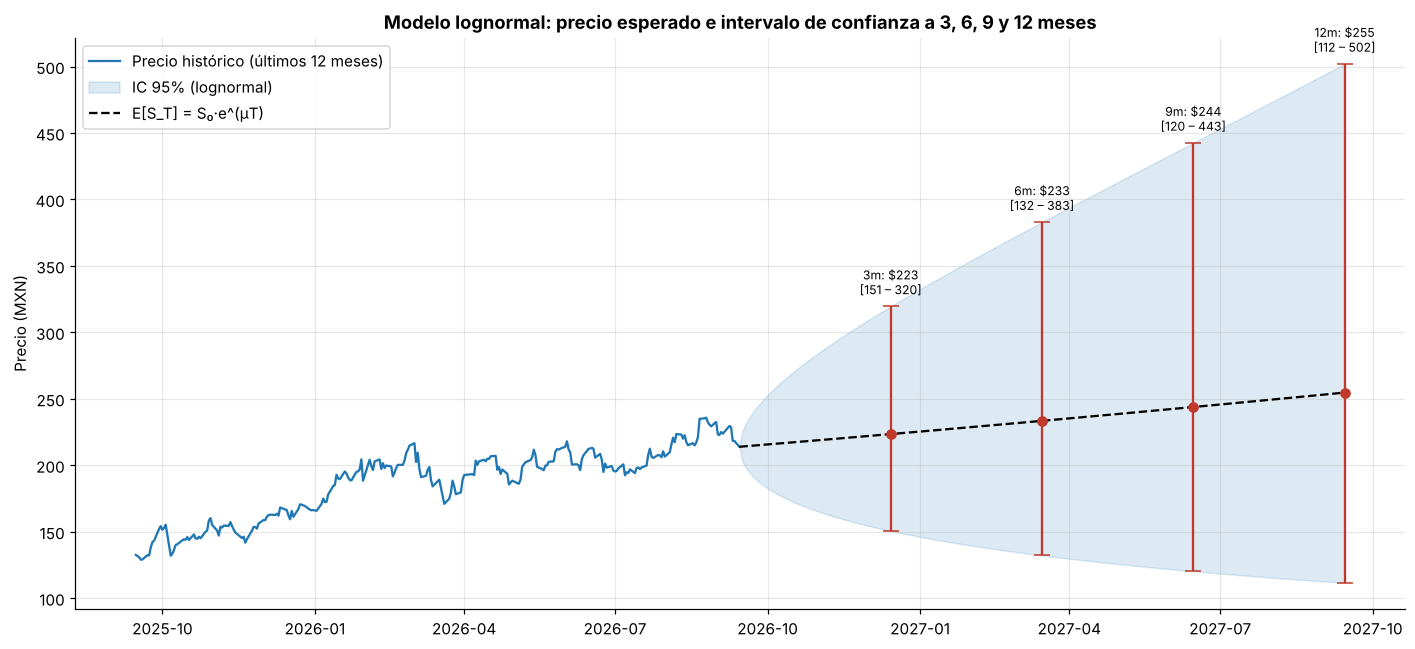

In [14]:
fig, ax = plt.subplots(figsize=(13, 6))

hist = df["adj_close"].loc[fecha_S0 - pd.Timedelta(days=365):]
ax.plot(hist.index, hist.values, color=AZUL, lw=1.5, label="Precio histórico (últimos 12 meses)")

T = np.linspace(0, 1, 200)
fechas = fecha_S0 + pd.to_timedelta(T * 365, unit="D")
centro = np.log(S0) + (mu_a - 0.5 * sig_a**2) * T
ax.fill_between(fechas, np.exp(centro - 1.96 * sig_a * np.sqrt(T)), np.exp(centro + 1.96 * sig_a * np.sqrt(T)),
                color=AZUL, alpha=0.15, label="IC 95% (lognormal)")
ax.plot(fechas, S0 * np.exp(mu_a * T), color="black", ls="--", lw=1.5, label="E[S_T] = S₀·e^(μT)")

for m in lognormal.index:
    f = lognormal.loc[m]
    x = fecha_S0 + pd.Timedelta(days=m / 12 * 365)
    ax.errorbar(x, f["E[S_T] teorico"], yerr=[[f["E[S_T] teorico"] - f["IC95 inf"]], [f["IC95 sup"] - f["E[S_T] teorico"]]],
                fmt="o", color=ROJO, capsize=5)
    ax.annotate(f"{m}m: ${f['E[S_T] teorico']:,.0f}\n[{f['IC95 inf']:,.0f} – {f['IC95 sup']:,.0f}]",
                (x, f["IC95 sup"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)

ax.set_title("Modelo lognormal: precio esperado e intervalo de confianza a 3, 6, 9 y 12 meses", fontweight="bold")
ax.set_ylabel("Precio (MXN)")
ax.legend(loc="upper left")
plt.tight_layout()
guardar(fig, "e3_modelo_lognormal_proyeccion")
plt.show()

> **Nota técnica.** El promedio de los rendimientos logarítmicos estima en realidad $\mu - \tfrac{1}{2}\sigma^2$,
> no $\mu$. Siguiendo las indicaciones, aquí se usó directamente como $\mu$, lo que hace que las proyecciones sean
> algo conservadoras (la mediana crece $\tfrac{1}{2}\sigma^2 \approx 7\%$ anual menos de lo que sugiere el historial).

## Parte 5 — Conclusión

In [15]:
sig_min, sig_max = anual_completos["sigma_anual"].min(), anual_completos["sigma_anual"].max()
f12 = lognormal.loc[12]
tend_10 = mu_d * 10
ruido_10 = sig_d * np.sqrt(10)

display(Markdown(f'''
**¿Los datos cumplen los supuestos del modelo?** No del todo. Los modelos suponen rendimientos normales,
independientes y con volatilidad constante. Los rendimientos de GMEXICOB rechazan la normalidad (curtosis de
{k_r:.2f} contra 3), y la volatilidad anual cambia mucho de un año a otro: de {pct(sig_min, 0)} en
{menos_vol} a {pct(sig_max, 0)} en {mas_vol}. El precio no es normal, lo cual sí es consistente con la teoría,
que predice un precio lognormal.

**¿Qué riesgos no capturan los intervalos?**

- **Colas pesadas:** hubo {ext["veces_mas"]:.1f} veces más días extremos (más de 3σ) de lo que predice la normal,
  así que el IC del 95% subestima la probabilidad de caídas fuertes como las de 2008 o 2020.
- **Volatilidad cambiante:** usar una sola σ de todo el historial ignora que hay periodos de crisis con el doble de
  volatilidad.
- **Choques y saltos:** eventos como la crisis de 2008, el COVID-19 o amenazas de aranceles al cobre generan
  saltos que el modelo no contempla.
- **Dependencia del cobre y factores externos:** precio del cobre, tipo de cambio y regulación minera no están en
  el modelo.
- **Incertidumbre en los parámetros:** el μ anual estimado tiene un IC de [{pct(ic_inf, 1)}, {pct(ic_sup, 1)}],
  y esa incertidumbre no se refleja en los intervalos.

**¿Tiene sentido usar una tendencia distinta de cero?** Sí. La prueba t rechaza μ = 0 (p = {tt["valor_p"]:.3f}),
así que incluir la tendencia está justificado. Pero en horizontes cortos casi no importa: a 10 días la tendencia
aporta {pct(tend_10)} contra un ruido de ±{pct(ruido_10)} (una desviación estándar). La volatilidad domina.

**¿Qué tan útiles son las estimaciones para decisiones reales?** Sirven para dimensionar el riesgo, no para
pronosticar. A 12 meses el rango va de {f12["IC95 inf"]:,.0f} a {f12["IC95 sup"]:,.0f} MXN, demasiado amplio para
decidir comprar o vender, pero útil para fijar límites de pérdida, tamaño de posición o escenarios de estrés.
Para decisiones reales convendría complementar con distribuciones de colas pesadas (t de Student), modelos de
volatilidad variable (GARCH) o simulación con rendimientos históricos.
'''))


**¿Los datos cumplen los supuestos del modelo?** No del todo. Los modelos suponen rendimientos normales,
independientes y con volatilidad constante. Los rendimientos de GMEXICOB rechazan la normalidad (curtosis de
7.79 contra 3), y la volatilidad anual cambia mucho de un año a otro: de 22% en
2012 a 70% en 2008. El precio no es normal, lo cual sí es consistente con la teoría,
que predice un precio lognormal.

**¿Qué riesgos no capturan los intervalos?**

- **Colas pesadas:** hubo 5.5 veces más días extremos (más de 3σ) de lo que predice la normal,
  así que el IC del 95% subestima la probabilidad de caídas fuertes como las de 2008 o 2020.
- **Volatilidad cambiante:** usar una sola σ de todo el historial ignora que hay periodos de crisis con el doble de
  volatilidad.
- **Choques y saltos:** eventos como la crisis de 2008, el COVID-19 o amenazas de aranceles al cobre generan
  saltos que el modelo no contempla.
- **Dependencia del cobre y factores externos:** precio del cobre, tipo de cambio y regulación minera no están en
  el modelo.
- **Incertidumbre en los parámetros:** el μ anual estimado tiene un IC de [2.9%, 32.0%],
  y esa incertidumbre no se refleja en los intervalos.

**¿Tiene sentido usar una tendencia distinta de cero?** Sí. La prueba t rechaza μ = 0 (p = 0.018),
así que incluir la tendencia está justificado. Pero en horizontes cortos casi no importa: a 10 días la tendencia
aporta 0.69% contra un ruido de ±7.65% (una desviación estándar). La volatilidad domina.

**¿Qué tan útiles son las estimaciones para decisiones reales?** Sirven para dimensionar el riesgo, no para
pronosticar. A 12 meses el rango va de 112 a 502 MXN, demasiado amplio para
decidir comprar o vender, pero útil para fijar límites de pérdida, tamaño de posición o escenarios de estrés.
Para decisiones reales convendría complementar con distribuciones de colas pesadas (t de Student), modelos de
volatilidad variable (GARCH) o simulación con rendimientos históricos.
